# 🎬 Render 3D Blender EEVEE Next (GPU Gratis) — *"Jangan Sampai Kunci Ini Jatuh!"*

Pipeline resmi **Blender 4.2 LTS Python (`bpy`) + EEVEE Next** untuk animasi YouTube Shorts 9:16 (58 detik, 6 lokasi, 28 gerakan kamera *continuous one-take*, karakter 3D rig terbuka, & audio narasi ElevenLabs).

### Cara Pakai:
1. Klik **Runtime → Change runtime type → T4 GPU** (wajib GPU agar EEVEE Next kencang!).
2. Isi `GITHUB_REPO_URL` di Sel 1 dengan URL repo GitHub project ini.
3. Jalankan Sel 1 → Sel 2 → **Sel 3 (Render 12 Preview Screenshot dulu untuk dinilai!)**.
4. Jika preview sudah cocok, jalankan **Sel 4** untuk merender video final 58 detik (1.740 frame) + muxing audio narasi ElevenLabs otomatis (dilengkapi *auto-resume*).

In [25]:
# === SEL 1: KONFIGURASI & CEK GPU COLAB ===
GITHUB_REPO_URL = "https://github.com/Genesys-ux/gg-colab.git"  # <-- Ganti dengan URL repo GitHub Anda!
REPO_BRANCH = "main"

USE_GOOGLE_DRIVE = True          # Simpan hasil .blend, frame & .mp4 otomatis ke Google Drive
DOWNLOAD_POLYHAVEN_PBR = True    # Unduh otomatis tekstur PBR CC0 1K (kayu, plaster, cobblestone, goni, karat)

# Resolusi Video Final (pilih 720x1280 lebih cepat atau 1080x1920 Full HD Shorts)
FINAL_WIDTH = 1080
FINAL_HEIGHT = 1920
EEVEE_SAMPLES = 32

!nvidia-smi

import os
DRIVE_OUT_DIR = "/content/drive/MyDrive/KunciJatuh_Blender3D"
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_OUT_DIR, exist_ok=True)
    print("Google Drive terhubung:", DRIVE_OUT_DIR)

Sun Nov 22 15:25:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   39C    P8             16W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [26]:
# === SEL 2: CLONE REPO GITHUB + INSTALL BLENDER 4.2 LTS (EGL GPU READY) ===
import os, re, shutil, subprocess, urllib.request

PROJECT_DIR = "/content/kunci_jatuh_3d"
if os.path.exists(PROJECT_DIR):
    print("Menyegarkan repo GitHub yang sudah ada...")
    !git -C {PROJECT_DIR} pull --ff-only
else:
    assert "USERNAME/REPO_ANDA" not in GITHUB_REPO_URL, "Silakan isi GITHUB_REPO_URL di Sel 1 terlebih dahulu!"
    !git clone --depth 1 -b {REPO_BRANCH} {GITHUB_REPO_URL} {PROJECT_DIR}

# Install dependensi EGL/OpenGL/Xvfb + FFmpeg untuk Blender EEVEE Next headless di Linux GPU
!apt-get -qq update
!apt-get -qq install -y libxi6 libunwind8 libgl1-mesa-dri libegl1-mesa libopengl0 libxkbcommon0 libsm6 libxrender1 xvfb ffmpeg

# Cari & unduh Blender 4.2 LTS Linux x64 terbaru dari server resmi Blender Foundation
BLENDER_DIR = "/content/blender_42"
BLENDER_BIN = os.path.join(BLENDER_DIR, "blender")
if not os.path.exists(BLENDER_BIN):
    base_url = "https://download.blender.org/release/Blender4.2/"
    tar_name = "blender-4.2.3-linux-x64.tar.xz"
    try:
        html = urllib.request.urlopen(base_url, timeout=15).read().decode("utf-8", errors="ignore")
        matches = re.findall(r"blender-4\.2\.\d+-linux-x64\.tar\.xz", html)
        if matches:
            tar_name = sorted(set(matches), key=lambda s: int(s.split(".")[2].split("-")[0]))[-1]
    except Exception as e:
        print("Gunakan versi fallback LTS:", tar_name, e)
    dl_url = base_url + tar_name
    print(f"Mengunduh {dl_url}...")
    !wget -q --show-progress {dl_url} -O /content/blender.tar.xz
    os.makedirs(BLENDER_DIR, exist_ok=True)
    !tar -xf /content/blender.tar.xz -C {BLENDER_DIR} --strip-components=1
    !rm -f /content/blender.tar.xz

!{BLENDER_BIN} --version

# Deteksi otomatis backend headless terbaik (NVIDIA EGL native vs xvfb-run fallback) lewat uji render EEVEE 64x64
os.environ["__EGL_VENDOR_LIBRARY_FILENAMES"] = "/usr/share/glvnd/egl_vendor.d/10_nvidia.json"
probe_py = (
    "import bpy; s=bpy.context.scene; "
    "e=[x.identifier for x in bpy.types.RenderSettings.bl_rna.properties['engine'].enum_items]; "
    "s.render.engine='BLENDER_EEVEE_NEXT' if 'BLENDER_EEVEE_NEXT' in e else 'BLENDER_EEVEE'; "
    "s.render.resolution_x=64; s.render.resolution_y=64; s.render.filepath='/tmp/eevee_probe.png'; "
    "bpy.ops.render.render(write_still=True); print('EEVEE_EGL_OK')"
)
res = subprocess.run([BLENDER_BIN, "-b", "--python-expr", probe_py], capture_output=True, text=True)
RUN_PREFIX = "" if (res.returncode == 0 and "EEVEE_EGL_OK" in res.stdout) else "xvfb-run -a "
print("Backend Blender Headless aktif:", "NVIDIA EGL Native" if not RUN_PREFIX else "Xvfb Virtual Display")

Menyegarkan repo GitHub yang sudah ada...
Already up to date.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
E: Unable to locate package libegl1-mesa
Blender 4.2.23 LTS
	build date: 2026-07-21
	build time: 01:31:03
	build commit date: 2026-07-20
	build commit time: 13:44
	build hash: d0cbe84903e8
	build branch: blender-v4.2-release
	build platform: Linux
	build type: Release
	build c flags:  -Wall -Werror=implicit-function-declaration -Wstrict-prototypes -Werror=return-type -Werror=vla -Wmissing-prototypes -Wno-char-subscripts -Wno-unknown-pragmas -Wpointer-arith -Wunused-parameter -Wwrite-strings -Wlogical-op -Wundef -Winit-self -Wmissing-include-dirs -Wno-div-by-zero -Wtype-limits -Wformat-signedness -Wrestrict -Wno-stringop-overread -Wno-stringop-overflow -Wnonnull -Wabsolute-value -Wuninitialized -Wredundant-decls -Wshadow -Wimplicit-fallthro

Streaming output truncated to the last 5000 lines.
Fra:1595 Mem:676.79M (Peak 722.05M) | Time:00:04.34 | Mem:280.26M, Peak:286.08M | Scene, ViewLayer | Updating Geometry BVH L5_PillarBase_-2.5_88 1105/1661 | Building OptiX acceleration structure
Fra:1595 Mem:676.79M (Peak 722.05M) | Time:00:04.34 | Mem:280.27M, Peak:286.08M | Scene, ViewLayer | Updating Geometry BVH L5_PillarCap_-2.5_88 1106/1661 | Building BVH
Fra:1595 Mem:676.79M (Peak 722.05M) | Time:00:04.34 | Mem:280.27M, Peak:286.08M | Scene, ViewLayer | Updating Geometry BVH L5_PillarCap_-2.5_88 1106/1661 | Building OptiX acceleration structure
Fra:1595 Mem:676.79M (Peak 722.05M) | Time:00:04.34 | Mem:280.27M, Peak:286.08M | Scene, ViewLayer | Updating Geometry BVH L5_Pillar_2.5_88 1107/1661 | Building BVH
Fra:1595 Mem:676.79M (Peak 722.05M) | Time:00:04.34 | Mem:280.27M, Peak:286.08M | Scene, ViewLayer | Updating Geometry BVH L5_Pillar_2.5_88 1107/1661 | Building OptiX acceleration structure
Fra:1595 Mem:676.80M (Peak 722.05M) 

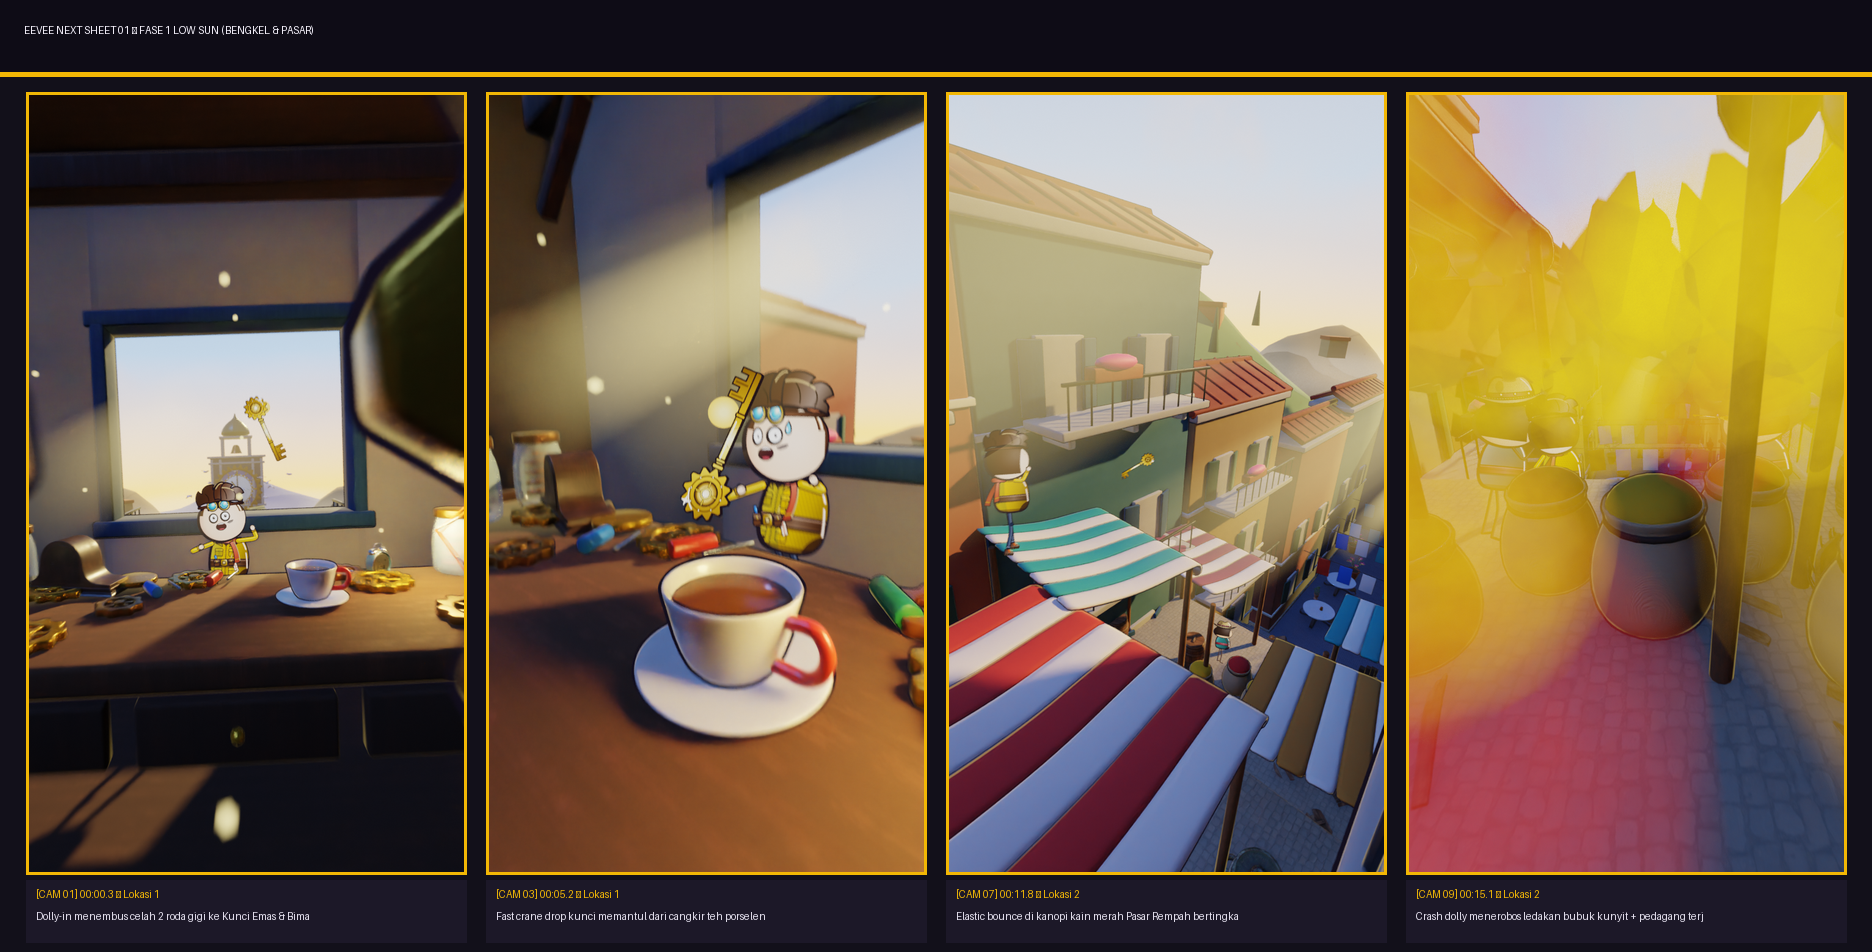

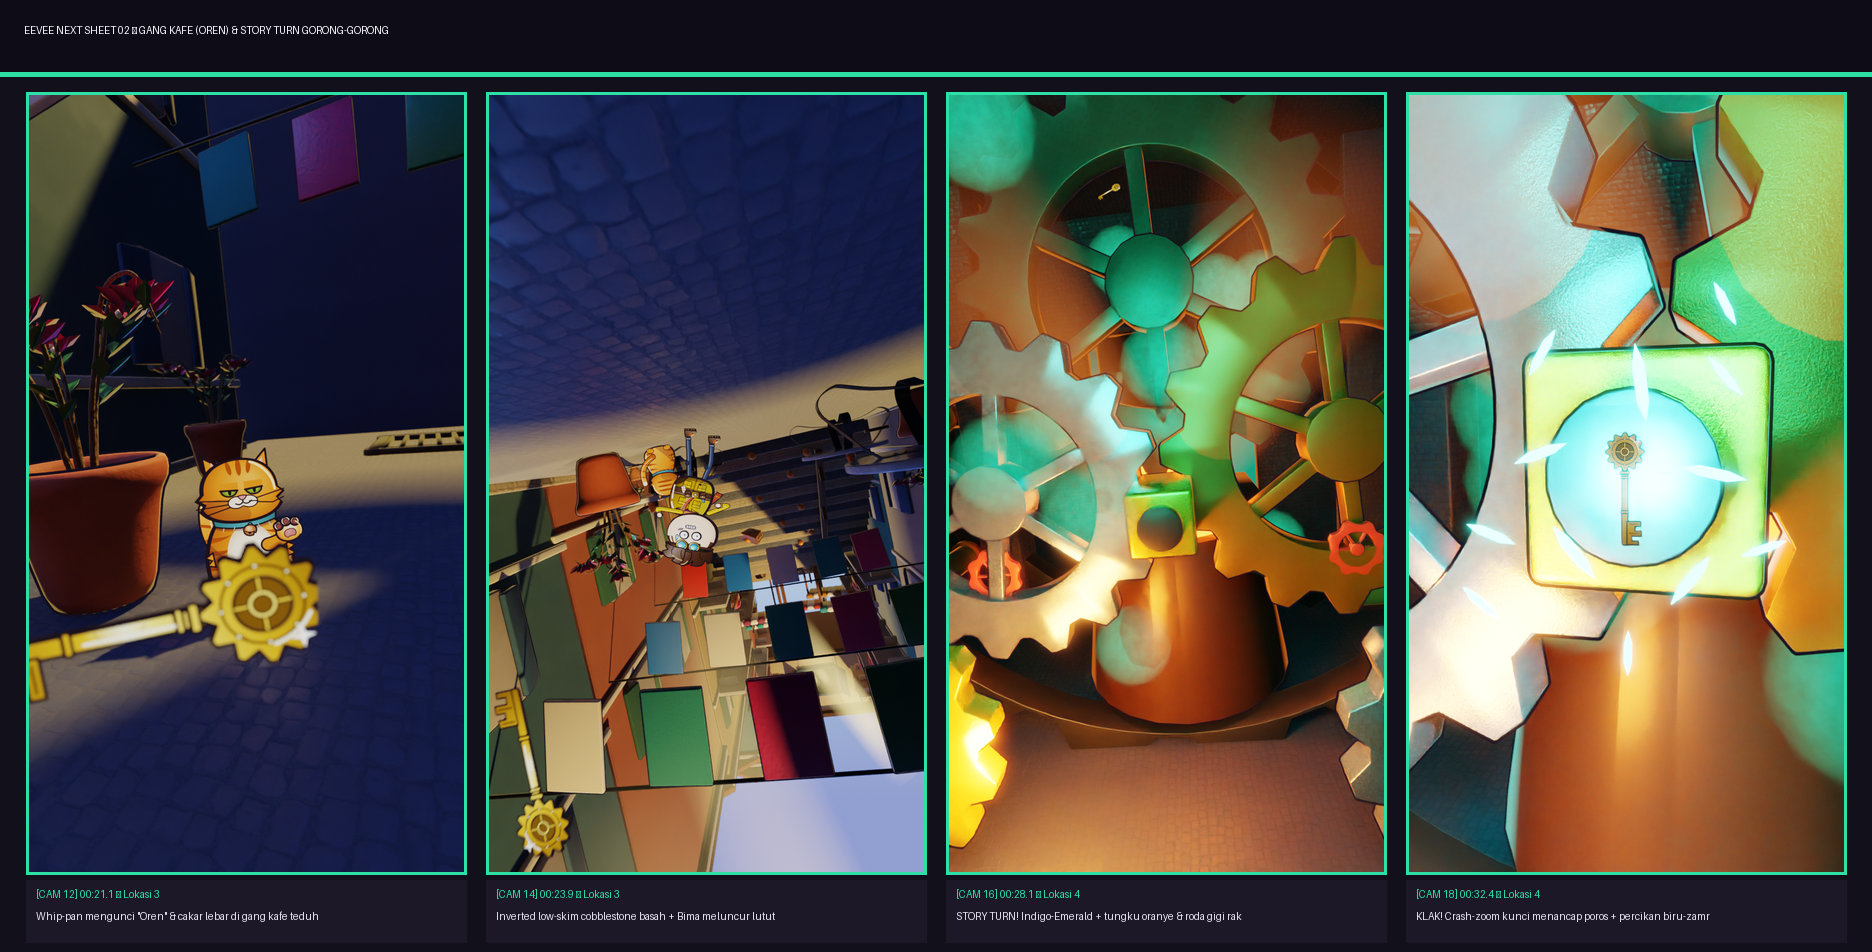

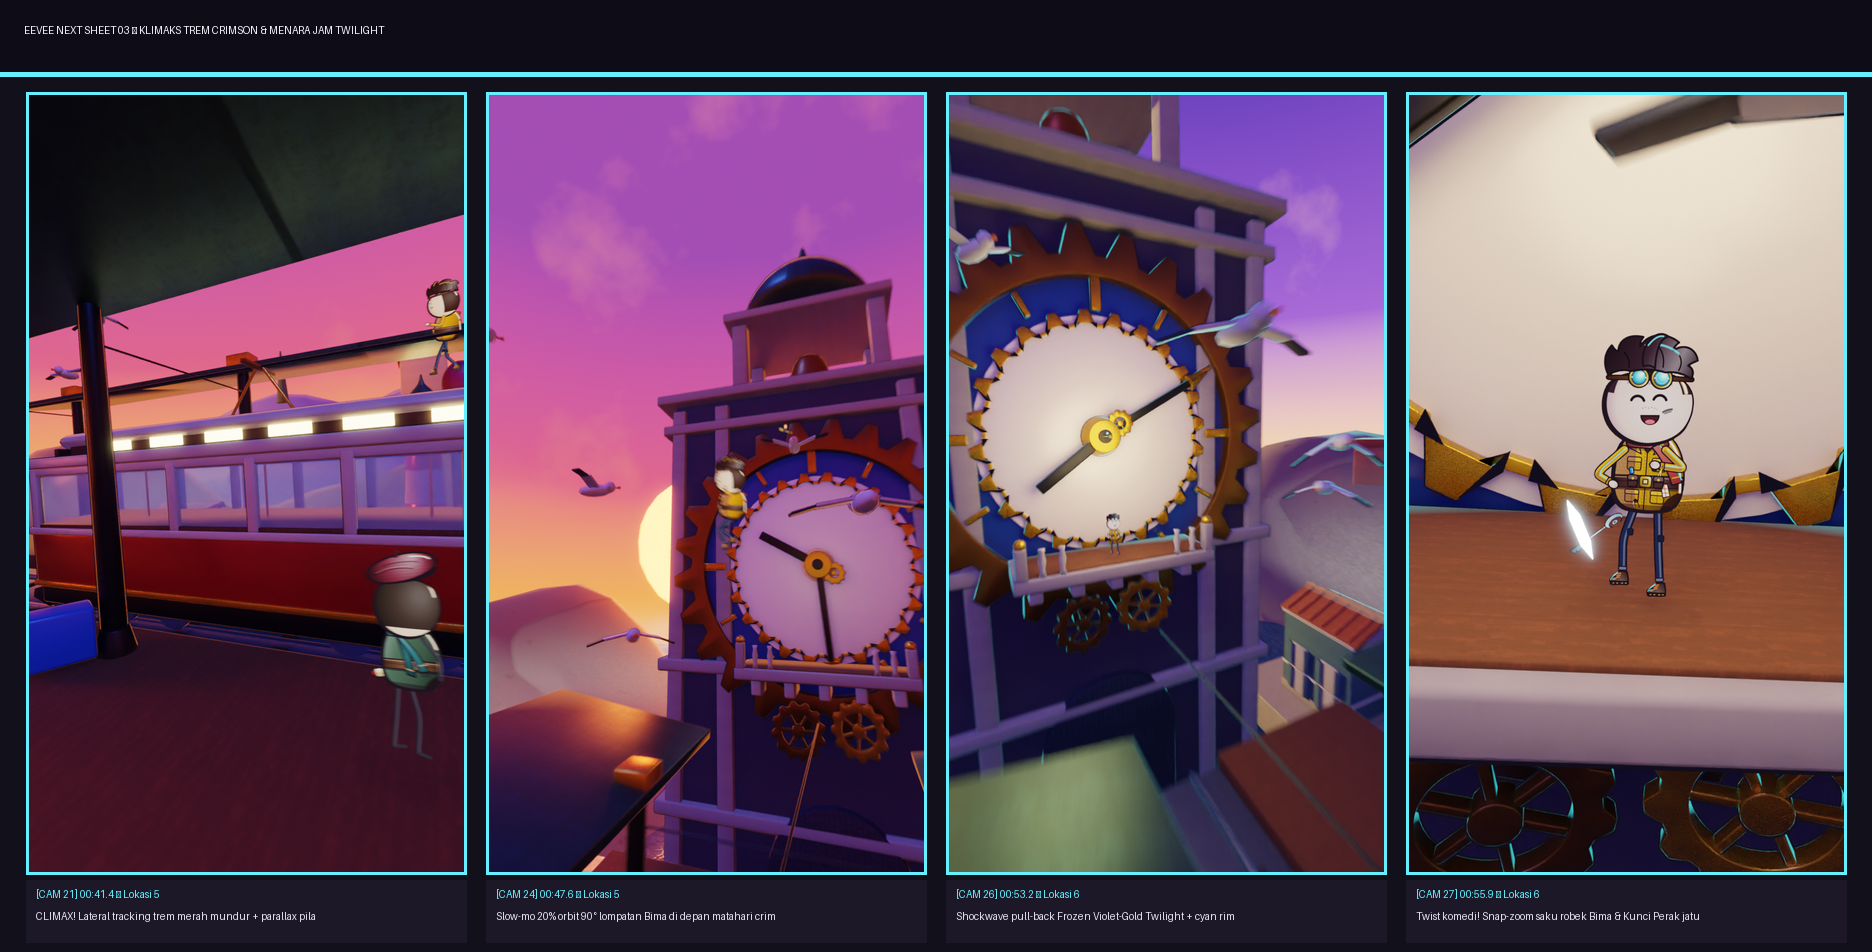

In [17]:
# === SEL 3: BANGUN SCENE 3D (.blend) & RENDER 12 PREVIEW SCREENSHOT EEVEE NEXT ===
import os, shutil
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Image as IPyImage

pbr_flag = "--download-pbr" if DOWNLOAD_POLYHAVEN_PBR else ""
cmd = (
    f"{RUN_PREFIX}{BLENDER_BIN} -b -P {PROJECT_DIR}/blender_pipeline/render_eevee.py -- "
    f"--mode previews --width 720 --height 1280 --samples {EEVEE_SAMPLES} {pbr_flag}"
)
print("Menjalankan:", cmd)
!{cmd}

# Rakit 3 Contact Sheet 4-panel beresolusi tajam & tampilkan langsung di Colab!
import sys
sys.path.insert(0, PROJECT_DIR)
from blender_pipeline.config import HERO_PREVIEW_SHOTS, PREVIEW_DIR, OUTPUT_DIR

def build_colab_sheet(title, accent, shot_slice, out_name):
    cw, ch, gap, pad = 440, 782, 20, 26
    w = pad * 2 + cw * 4 + gap * 3
    h = 92 + ch + 78
    sheet = Image.new("RGB", (w, h), (18, 16, 26))
    draw = ImageDraw.Draw(sheet)
    draw.rectangle([0, 0, w, 76], fill=(14, 12, 22))
    draw.rectangle([0, 72, w, 76], fill=accent)
    draw.text((24, 24), title, fill=(248, 245, 255))
    for idx, (fname, _t, badge, desc) in enumerate(shot_slice):
        fp = os.path.join(PREVIEW_DIR, fname)
        if not os.path.exists(fp):
            continue
        x0, y0 = pad + idx * (cw + gap), 92
        im = Image.open(fp).convert("RGB").resize((cw, ch), Image.Resampling.LANCZOS)
        sheet.paste(im, (x0, y0))
        draw.rectangle([x0, y0, x0 + cw, y0 + ch], outline=accent, width=3)
        draw.rectangle([x0, y0 + ch + 6, x0 + cw, y0 + ch + 68], fill=(28, 24, 40))
        draw.text((x0 + 10, y0 + ch + 14), badge, fill=accent)
        draw.text((x0 + 10, y0 + ch + 36), desc[:58], fill=(230, 226, 240))
    out_p = os.path.join(PREVIEW_DIR, out_name)
    sheet.save(out_p, quality=94)
    if USE_GOOGLE_DRIVE:
        shutil.copy2(out_p, os.path.join(DRIVE_OUT_DIR, out_name))
    return out_p

sheets = [
    build_colab_sheet("EEVEE NEXT SHEET 01 — FASE 1 LOW SUN (BENGKEL & PASAR)", (242, 183, 5), HERO_PREVIEW_SHOTS[0:4], "eevee_sheet_01_fase1.png"),
    build_colab_sheet("EEVEE NEXT SHEET 02 — GANG KAFE (OREN) & STORY TURN GORONG-GORONG", (46, 224, 166), HERO_PREVIEW_SHOTS[4:8], "eevee_sheet_02_story_turn.png"),
    build_colab_sheet("EEVEE NEXT SHEET 03 — KLIMAKS TREM CRIMSON & MENARA JAM TWILIGHT", (102, 240, 255), HERO_PREVIEW_SHOTS[8:12], "eevee_sheet_03_climax_finale.png"),
]
if USE_GOOGLE_DRIVE:
    blend_src = os.path.join(OUTPUT_DIR, "jangan_sampai_kunci_ini_jatuh.blend")
    if os.path.exists(blend_src):
        shutil.copy2(blend_src, os.path.join(DRIVE_OUT_DIR, "jangan_sampai_kunci_ini_jatuh.blend"))
        print("File .blend tersalin ke Google Drive (siap dibuka manual di Blender Windows!)")

for sp in sheets:
    display(IPyImage(filename=sp, width=1000))

In [28]:
import os, shutil

# TAB 1 isi: START_FRAME = 1,    END_FRAME = 1050  (otomatis lewati 356+ frame yang sudah jadi!)
# TAB 2 isi: START_FRAME = 1051, END_FRAME = 1740
START_FRAME = 1
END_FRAME = 1050

BLEND_FILE = f"{PROJECT_DIR}/output/jangan_sampai_kunci_ini_jatuh.blend"
if not os.path.exists(BLEND_FILE):
    for nm in ("jangan_sampai_kunci_ini_jatuh.blend", "jangan_sampai_kunci_ini_jatuh_v2.blend"):
        src = os.path.join(DRIVE_OUT_DIR, nm)
        if os.path.exists(src):
            os.makedirs(f"{PROJECT_DIR}/output", exist_ok=True)
            shutil.copy2(src, BLEND_FILE)
            print("Memuat .blend dari Drive:", src)
            break

drive_frames = os.path.join(DRIVE_OUT_DIR, f"frames_{FINAL_WIDTH}x{FINAL_HEIGHT}")
os.makedirs(drive_frames, exist_ok=True)
local_frames = f"{PROJECT_DIR}/output/frames"
if os.path.islink(local_frames): os.unlink(local_frames)
elif os.path.isdir(local_frames): shutil.rmtree(local_frames)
os.makedirs(f"{PROJECT_DIR}/output", exist_ok=True)
os.symlink(drive_frames, local_frames)

FINAL_MP4 = f"{PROJECT_DIR}/output/jangan_sampai_kunci_ini_jatuh_final_{FINAL_WIDTH}x{FINAL_HEIGHT}.mp4"
!{BLENDER_BIN} -b -P {PROJECT_DIR}/blender_pipeline/render_eevee.py -- \
  --mode video --engine CYCLES --blend-in {BLEND_FILE} \
  --width {FINAL_WIDTH} --height {FINAL_HEIGHT} --samples 24 \
  --start-frame {START_FRAME} --end-frame {END_FRAME} --download-assets --pbr-res 2k \
  --resume --out-mp4 {FINAL_MP4}

if os.path.exists(FINAL_MP4):
    shutil.copy2(FINAL_MP4, os.path.join(DRIVE_OUT_DIR, os.path.basename(FINAL_MP4)))
    print("SELESAI! Video final tersimpan di Google Drive:", DRIVE_OUT_DIR)

Streaming output truncated to the last 5000 lines.
Fra:1049 Mem:1316.68M (Peak 1384.39M) | Time:00:03.13 | Mem:1236.15M, Peak:1281.65M | Scene, ViewLayer | Updating Geometry BVH L4_EmeraldSteam_11 997/1636 | Building OptiX acceleration structure
Fra:1049 Mem:1316.68M (Peak 1384.39M) | Time:00:03.13 | Mem:1236.15M, Peak:1281.65M | Scene, ViewLayer | Updating Geometry BVH L4_KlakSpark_0 998/1636 | Building BVH
Fra:1049 Mem:1316.68M (Peak 1384.39M) | Time:00:03.13 | Mem:1236.17M, Peak:1281.65M | Scene, ViewLayer | Updating Geometry BVH L4_KlakSpark_0 998/1636 | Building OptiX acceleration structure
Fra:1049 Mem:1316.67M (Peak 1384.39M) | Time:00:03.13 | Mem:1236.15M, Peak:1281.65M | Scene, ViewLayer | Updating Geometry BVH L6_HarborSeagull_6_WingIn_L 1547/1636 | Building BVH
Fra:1049 Mem:1316.67M (Peak 1384.39M) | Time:00:03.13 | Mem:1236.14M, Peak:1281.65M | Scene, ViewLayer | Updating Geometry BVH L6_HarborSeagull_6_WingIn_L 1547/1636 | Building OptiX acceleration structure
Fra:1049 Mem

In [4]:
import glob, os, subprocess
from google.colab import drive, files

# 1. Mount Google Drive
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

# 2. Cari otomatis folder frames (KunciJatuh_Blender3D atau KunciJatuh_Blender3D_v2)
candidates = sorted(glob.glob("/content/drive/MyDrive/KunciJatuh_Blender3D*/frames_*"))
assert candidates, "Folder frames tidak ditemukan di Google Drive!"
FRAMES_DIR = max(candidates, key=lambda d: len(glob.glob(os.path.join(d, "frame_*.png"))))
DRIVE_OUT_DIR = os.path.dirname(FRAMES_DIR)

pngs = sorted(glob.glob(os.path.join(FRAMES_DIR, "frame_*.png")))
print(f"Folder frames ditemukan: {FRAMES_DIR} ({len(pngs)} / 1740 frame)")
missing = [f for f in range(1, 1741) if not os.path.exists(os.path.join(FRAMES_DIR, f"frame_{f:04d}.png"))]
if missing:
    print(f"PERINGATAN: Masih ada {len(missing)} frame belum ada: {missing[:15]}")
else:
    print("LENGKAP! Semua 1.740 frame (0001..1740) tersedia.")

# 3. Cari audio narasi ElevenLabs (jika VM baru restart, isi GITHUB_REPO_URL di bawah agar otomatis diambil)
GITHUB_REPO_URL = "https://github.com/Genesys-ux/gg-colab.git"  # <-- Opsional: isi URL repo GitHub Anda jika audio belum ada di /content/kunci_jatuh_3d
AUDIO_PATH = None
for ap in (
    "/content/kunci_jatuh_3d/audio/output/narration_master_58s.wav",
    "/content/kunci_jatuh_3d/audio/output/narration_master_58s.mp3",
    os.path.join(DRIVE_OUT_DIR, "narration_master_58s.wav"),
    os.path.join(DRIVE_OUT_DIR, "narration_master_58s.mp3"),
):
    if os.path.exists(ap):
        AUDIO_PATH = ap
        break

if AUDIO_PATH is None and GITHUB_REPO_URL:
    subprocess.run(["git", "clone", "--depth", "1", GITHUB_REPO_URL, "/content/kunci_jatuh_3d"], check=True)
    for ap in (
        "/content/kunci_jatuh_3d/audio/output/narration_master_58s.wav",
        "/content/kunci_jatuh_3d/audio/output/narration_master_58s.mp3",
    ):
        if os.path.exists(ap):
            AUDIO_PATH = ap
            break

print("Audio narasi:", AUDIO_PATH or "(Belum ditemukan — akan digabung video dulu; isi GITHUB_REPO_URL untuk sertakan suara!)")

# 4. Gabung 1.740 PNG + Audio ElevenLabs -> MP4 Final (1080x1920 30fps H.264)
OUT_MP4 = os.path.join(DRIVE_OUT_DIR, "jangan_sampai_kunci_ini_jatuh_FINAL_58s.mp4")
cmd = [
    "ffmpeg", "-y", "-v", "warning", "-stats",
    "-framerate", "30",
    "-i", os.path.join(FRAMES_DIR, "frame_%04d.png"),
]
if AUDIO_PATH:
    cmd += ["-i", AUDIO_PATH]
cmd += ["-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "16", "-preset", "medium", "-movflags", "+faststart"]
if AUDIO_PATH:
    cmd += ["-c:a", "aac", "-b:a", "192k", "-shortest"]
cmd.append(OUT_MP4)

subprocess.run(cmd, check=True)
print("\nSELESAI! Video final tersimpan di Google Drive:", OUT_MP4)
files.download(OUT_MP4)

Folder frames ditemukan: /content/drive/MyDrive/KunciJatuh_Blender3D/frames_1080x1920 (1740 / 1740 frame)
LENGKAP! Semua 1.740 frame (0001..1740) tersedia.
Audio narasi: /content/kunci_jatuh_3d/audio/output/narration_master_58s.wav

SELESAI! Video final tersimpan di Google Drive: /content/drive/MyDrive/KunciJatuh_Blender3D/jangan_sampai_kunci_ini_jatuh_FINAL_58s.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>